## Part 1: Explore the instructor-provided embeddings

Inspect the supplied 2023 data, align papers and vectors by PMID, and explore three principal components. Run the cells in order. Code and explanatory notes were prepared with Codex assistance.


### 1. Load and inspect paper metadata

Read the PMID-keyed metadata dictionary and inspect the title, abstract sections, and query label of one paper.


In [18]:
import json
from pathlib import Path

folder = Path(
    "/Users/marco/Documents/Fall2026/02-courses/"
    "bis-cbb-634/github-repo/data-exploration-exercises"
)

with open(folder / "papers.json", encoding="utf-8") as f:
    papers = json.load(f)

print("Data type:", type(papers))
print("Number of papers:", len(papers))

# Inspect the first paper
first_pmid = next(iter(papers))
print("First PMID:", first_pmid)
print("Available fields:", papers[first_pmid].keys())

papers[first_pmid]

Data type: <class 'dict'>
Number of papers: 1995
First PMID: 37961728
Available fields: dict_keys(['AbstractText', 'ArticleTitle', 'query'])


{'AbstractText': [{'section': 'BACKGROUND',
   'text': "Direct oral anticoagulants (DOACs) outperform warfarin in vascular and bleeding events in atrial fibrillation (AF) patients. Yet, effects of DOACs on congestive heart failure (CHF) and Alzheimer's disease (AD) remain less explored."},
  {'section': 'METHODS',
   'text': 'Using the Taiwan National Health Insurance Research Database, a nationwide retrospective cohort study was conducted. The study matched 5,683 non-valvular atrial fibrillation (NVAF) edoxaban patients with 11,366 warfarin patients, and 703 NVAF with cancer (NVAF-C) edoxaban patients with 1,406 warfarin patients. Vasular and non-vascular outcomes, with focuses on CHF and AD, were compared between the edoxaban and warfarin users.'},
  {'section': 'RESULTS',
   'text': 'Edoxaban significantly lowered adjusted hazrad ratio (aHR) of all-cause mortality, hospitalization for gastrointestinal bleeding, and CHF (0.37, 0.74, and 0.26, respectively, in NVAF; 0.39, 0.67, and 0.

### 2. Read the supplied embedding database

Open the instructor-provided shelf in read-only mode using its base name. Each PMID maps to a 768-dimensional NumPy vector.


In [19]:
import shelve
import numpy as np

with shelve.open(str(folder / "embeddings"), flag="r") as db:
    embeddings = {pmid: db[pmid] for pmid in db}

print("Data type:", type(embeddings))
print("Number of embeddings:", len(embeddings))

# Inspect the embedding for the first paper
first_pmid = next(iter(papers))
vector = embeddings[first_pmid]

print("PMID:", first_pmid)
print("Vector type:", type(vector))
print("Vector shape:", vector.shape)

vector

Data type: <class 'dict'>
Number of embeddings: 1995
PMID: 37961728
Vector type: <class 'numpy.ndarray'>
Vector shape: (768,)


array([-3.89155567e-01,  1.09271550e+00,  1.06197429e+00, -7.56747797e-02,
        3.84014845e-01,  3.01766723e-01, -1.80439949e-01,  9.41143095e-01,
        1.76635176e-01,  1.08489358e+00, -8.27979565e-01, -1.93561524e-01,
        3.41359638e-02, -5.03421485e-01, -6.41940594e-01,  4.21897680e-01,
       -8.54471803e-01, -3.86720523e-02,  7.88620174e-01, -5.63121140e-01,
       -4.94078733e-03,  3.91656935e-01,  8.27851593e-01,  1.81609678e+00,
       -5.65699279e-01, -3.50890160e-01,  4.69105184e-01, -1.03732133e+00,
        8.59434485e-01,  1.28121540e-01,  4.79216486e-01,  3.61535728e-01,
       -3.34302694e-01,  1.22468732e-01, -1.20465684e+00, -3.77909571e-01,
        1.58077270e-01,  4.62520838e-01,  2.00265825e-01, -8.64223123e-01,
       -6.41775206e-02,  1.35472083e+00,  2.43201181e-01,  1.52831256e-01,
        8.19859684e-01, -6.48294687e-01,  2.67827541e-01, -7.92794585e-01,
       -8.43440071e-02,  1.42203820e+00, -5.75342059e-01,  1.72904283e-01,
        7.88316846e-01,  

### 3. Align vectors and labels by PMID

Check the PMID sets and use one shared ordering for the embedding matrix and query labels.


In [20]:
import numpy as np

# Check that both sources contain exactly the same PMIDs
missing = set(papers) - set(embeddings)
extra = set(embeddings) - set(papers)

print("PMIDs without embeddings:", len(missing))
print("PMIDs without metadata:", len(extra))

if missing or extra:
    raise ValueError("The PMID sets do not match.")

# Use one shared PMID order for vectors and labels
pmids = sorted(papers.keys())

X = np.stack([embeddings[pmid] for pmid in pmids])
labels = np.array([papers[pmid]["query"] for pmid in pmids])

print("Embedding matrix shape:", X.shape)
print("Label array shape:", labels.shape)

# Inspect the first aligned record
print("First PMID:", pmids[0])
print("Title:", papers[pmids[0]]["ArticleTitle"])
print("Label:", labels[0])
print("First 10 embedding values:", X[0, :10])

PMIDs without embeddings: 0
PMIDs without metadata: 0
Embedding matrix shape: (1995, 768)
Label array shape: (1995,)
First PMID: 37878811
Title: Community-Engaged Research with Latino Dementia Caregivers: Overcoming Challenges in Community Advisory Board Development.
Label: Alzheimers
First 10 embedding values: [-0.68299776  0.2428854   0.43429184 -0.33548552 -0.10964363 -0.38772273
 -0.13327324 -0.14259332  0.74525315  0.30849445]


### 4. Fit PCA and inspect explained variance

Center the embedding features and project onto three principal components without using the query labels.


In [21]:
from sklearn.decomposition import PCA

# Check that all embedding values are finite
if not np.isfinite(X).all():
    raise ValueError("The embedding matrix contains NaN or infinite values.")

# Create a PCA model that retains three principal components
pca = PCA(n_components=3)

# Fit PCA to the embeddings and project them onto the new axes
X_pca = pca.fit_transform(X)

# Inspect the projected data
print("Original shape:", X.shape)
print("Projected shape:", X_pca.shape)
print("First paper coordinates:", X_pca[0])

# Report the fraction of total variance explained by each component
variance_ratios = pca.explained_variance_ratio_

for i, ratio in enumerate(variance_ratios):
    print(f"PC{i}: {ratio:.2%} explained variance")

print(f"Combined explained variance: {variance_ratios.sum():.2%}")

Original shape: (1995, 768)
Projected shape: (1995, 3)
First paper coordinates: [-4.2297287 -5.6401944  4.114532 ]
PC0: 16.62% explained variance
PC1: 6.79% explained variance
PC2: 4.53% explained variance
Combined explained variance: 27.95%


### 5. Plot the three component pairs

Display three two-dimensional views of the same PCA fit, with consistent query colors.


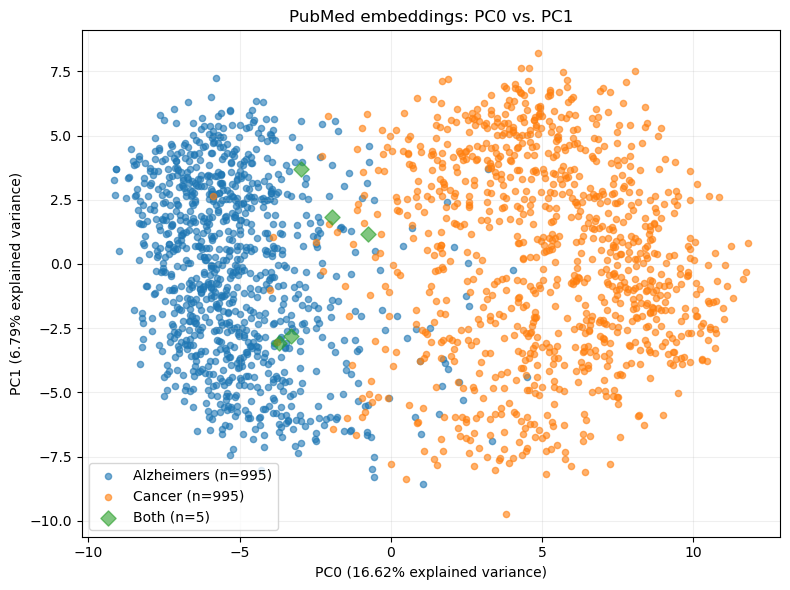

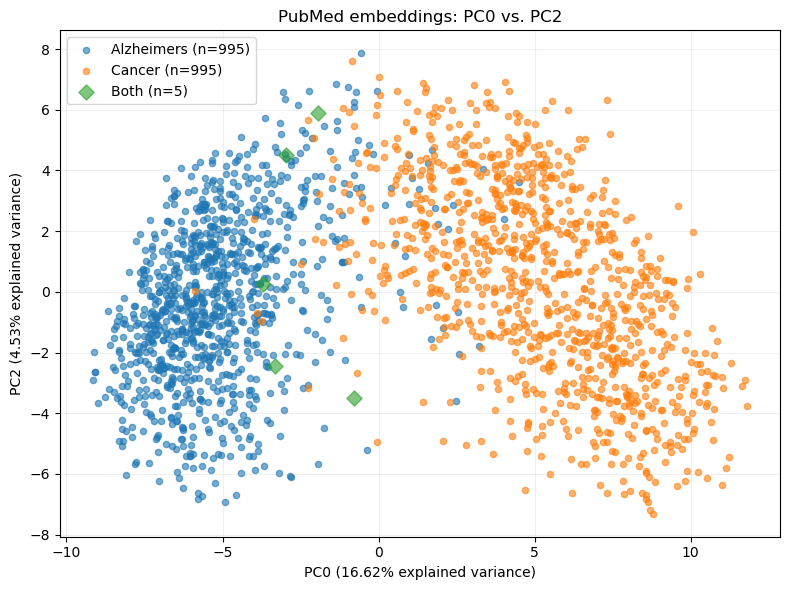

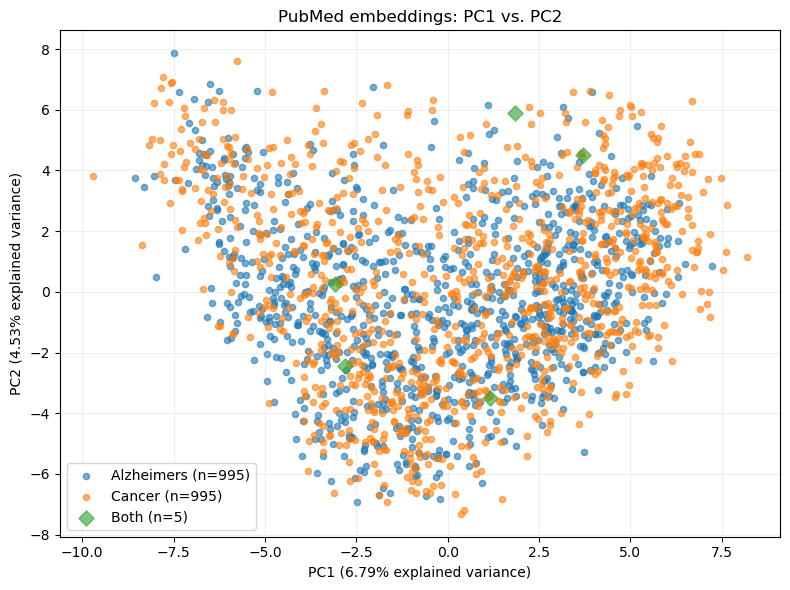

In [23]:
import matplotlib.pyplot as plt

# Define a consistent color for each query label
colors = {
    "Alzheimers": "tab:blue",
    "Cancer": "tab:orange",
    "Both": "tab:green",
}

# Define the three pairs of principal components
component_pairs = [(0, 1), (0, 2), (1, 2)]

# Get the explained variance ratio for each component
variance_ratios = pca.explained_variance_ratio_

# Create one scatter plot for each component pair
for x_component, y_component in component_pairs:
    fig, ax = plt.subplots(figsize=(8, 6))

    # Plot each label group separately
    for label, color in colors.items():
        mask = labels == label

        ax.scatter(
            X_pca[mask, x_component],
            X_pca[mask, y_component],
            color=color,
            label=f"{label} (n={mask.sum()})",
            alpha=0.6,
            s=60 if label == "Both" else 20,
            marker="D" if label == "Both" else "o",
        )

    # Label the axes with component names and explained variance
    ax.set_xlabel(
        f"PC{x_component} "
        f"({variance_ratios[x_component]:.2%} explained variance)"
    )
    ax.set_ylabel(
        f"PC{y_component} "
        f"({variance_ratios[y_component]:.2%} explained variance)"
    )

    ax.set_title(f"PubMed embeddings: PC{x_component} vs. PC{y_component}")
    ax.legend()
    ax.grid(alpha=0.2)

    # Adjust spacing and display the figure
    fig.tight_layout()
    plt.show()

### 6. Explore an interactive 3D view

Rotate the plot and hover over points to identify their PMIDs and titles.


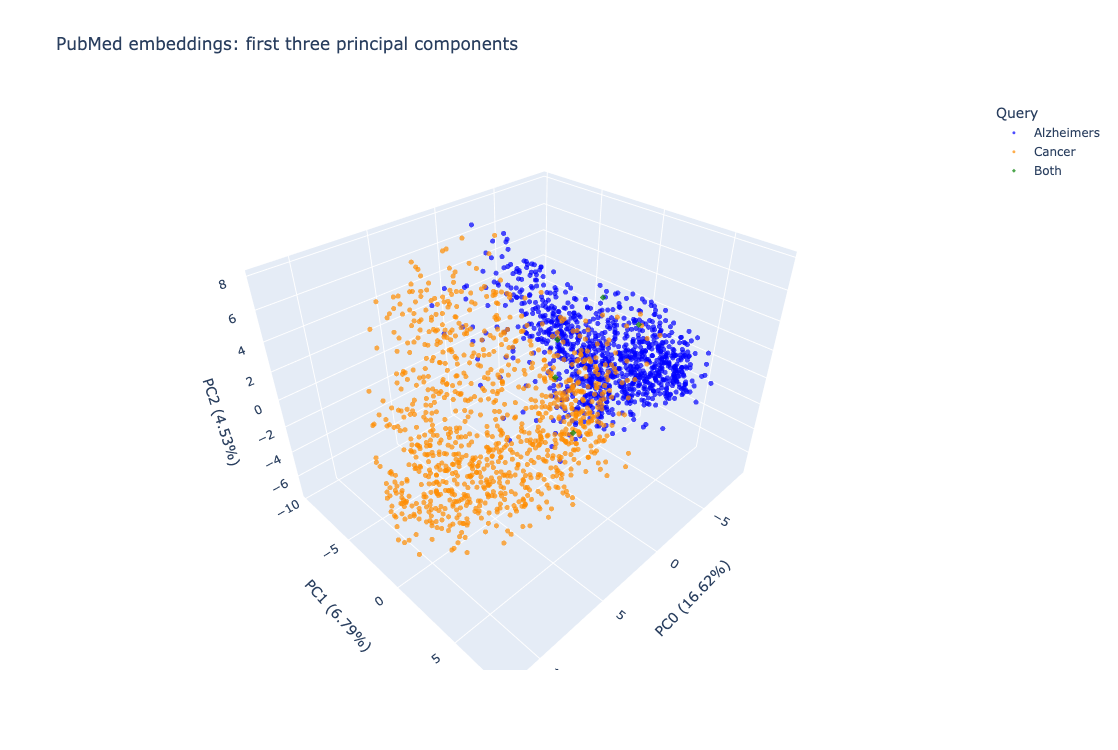

In [24]:
import pandas as pd
import plotly.express as px

# Keep coordinates, labels, and metadata in the same PMID order
plot_data = pd.DataFrame({
    "PC0": X_pca[:, 0],
    "PC1": X_pca[:, 1],
    "PC2": X_pca[:, 2],
    "Query": labels,
    "PMID": pmids,
    "Title": [papers[pmid]["ArticleTitle"] for pmid in pmids],
})

# Create an interactive 3D scatter plot
fig = px.scatter_3d(
    plot_data,
    x="PC0",
    y="PC1",
    z="PC2",
    color="Query",
    symbol="Query",
    color_discrete_map={
        "Alzheimers": "blue",
        "Cancer": "darkorange",
        "Both": "green",
    },
    symbol_map={
        "Alzheimers": "circle",
        "Cancer": "circle",
        "Both": "diamond",
    },
    hover_name="PMID",
    hover_data={"Title": True},
    opacity=0.7,
    title="PubMed embeddings: first three principal components",
    height=750,
)

# Label each axis with its explained variance
variance_ratios = pca.explained_variance_ratio_

fig.update_layout(
    scene={
        "xaxis_title": f"PC0 ({variance_ratios[0]:.2%})",
        "yaxis_title": f"PC1 ({variance_ratios[1]:.2%})",
        "zaxis_title": f"PC2 ({variance_ratios[2]:.2%})",
        "aspectmode": "data",
    }
)

fig.update_traces(marker={"size": 3})
fig.show()

### 7. Define a paper-inspection helper

Retrieve local metadata and PCA coordinates for a selected PMID; this does not automatically identify outliers.


In [25]:
import textwrap

def inspect_paper(pmid):
    """Display metadata and PCA coordinates for a selected paper."""
    pmid = str(pmid).strip()

    if pmid not in papers:
        print(f"PMID {pmid} was not found.")
        return

    paper = papers[pmid]

    print("PMID:", pmid)
    print("Query label:", paper["query"])
    print("PubMed URL:", f"https://pubmed.ncbi.nlm.nih.gov/{pmid}/")

    print("\nTitle:")
    print(textwrap.fill(paper["ArticleTitle"], width=100))

    # Find the row corresponding to this PMID
    row = pmids.index(pmid)
    print("\nPCA coordinates:")
    for component, value in enumerate(X_pca[row]):
        print(f"PC{component}: {value:.4f}")

    # Display each abstract section
    print("\nAbstract:")
    abstract = paper.get("AbstractText")

    if not abstract:
        print("No abstract available.")
    elif isinstance(abstract, str):
        print(textwrap.fill(abstract, width=100))
    else:
        for section in abstract:
            heading = section.get("section", "")
            text = section.get("text", "")

            if heading:
                print(f"\n{heading}")
            print(textwrap.fill(text, width=100))

### 8. Inspect a selected paper

This optional cell waits for a PMID. Answer the prompt or skip the cell when continuing to Part 2; Run All will wait here.


In [27]:
# Enter the PMID shown when hovering over a point
selected_pmid = input("Enter a PMID: ").strip()

inspect_paper(selected_pmid)

Enter a PMID:  37972804


PMID: 37972804
Query label: Cancer
PubMed URL: https://pubmed.ncbi.nlm.nih.gov/37972804/

Title:
Neuron navigators: A novel frontier with physiological and pathological implications.

PCA coordinates:
PC0: -3.8917
PC1: 1.0506
PC2: -0.6879

Abstract:
Neuron navigators are microtubule plus-end tracking proteins containing basic and serine rich
regions which are encoded by neuron navigator genes (NAVs). Neuron navigator proteins are essential
for neurite outgrowth, neuronal migration, and overall neurodevelopment along with some other
functions as well. The navigator proteins are substantially expressed in the developing brain and
have been reported to be differentially expressed in various tissues at different ages. Over the
years, the research has found neuron navigators to be implicated in a spectrum of pathological
conditions such as developmental anomalies, neurodegenerative disorders, neuropathic pain, anxiety,
cancers, and certain inflammatory conditions. The existing knowledge abo

## Part 2: Configurable PubMed-to-SPECTER pipeline

Edit only the configuration cell to change the year, the two search groups, or the requested count. Run Part 2 from the configuration cell downward after restarting the kernel. The dependency cell is optional if the packages are installed.

The original configuration reuses the existing 2025 files. Other configurations receive separate filenames. Change `RUN_TAG` to retrieve a fresh sample with otherwise identical settings. Searches use publication-date order, not random sampling; an ongoing year is incomplete. `Both` means membership in both retrieved PMID sets.

Code was refactored with Codex assistance. Saved outputs reflect the execution state of each cell. The README discussion was organized with Codex assistance; see its AI assistance disclosure.


In [1]:
%pip install torch transformers scikit-learn matplotlib pandas requests tqdm plotly

Note: you may need to restart the kernel to use updated packages.


### Configuration

In [2]:
import json
import hashlib
from pathlib import Path

# Change these settings before starting a new run.
YEAR = 2025
SEARCH_TERMS = {
    "Alzheimers": "Alzheimer's disease",
    "Cancer": "Cancer",
}
PAPERS_PER_QUERY = 1000
SORT_ORDER = "pub_date"
FETCH_BATCH_SIZE = 100
EMBEDDING_BATCH_SIZE = 8
MAX_LENGTH = 512
MODEL_NAME = "allenai/specter"
MODEL_REVISION = "main"
# Change this tag to start a fresh retrieval with the same search settings.
RUN_TAG = "initial"
FOLDER = Path(
    "/Users/marco/Documents/Fall2026/02-courses/"
    "bis-cbb-634/github-repo/data-exploration-exercises"
)

# The remaining settings are derived automatically.
if len(SEARCH_TERMS) != 2 or "Both" in SEARCH_TERMS:
    raise ValueError("Provide exactly two labels; 'Both' is reserved.")
if not all(label.strip() and term.strip() for label, term in SEARCH_TERMS.items()):
    raise ValueError("Labels and search terms must not be empty.")
if not 3 <= PAPERS_PER_QUERY <= 10000:
    raise ValueError("PAPERS_PER_QUERY must be between 3 and 10000.")
if FETCH_BATCH_SIZE < 1 or FETCH_BATCH_SIZE > 100 or EMBEDDING_BATCH_SIZE < 1:
    raise ValueError("Use fetch batches of 1-100 and a positive embedding batch size.")
if not 1 <= MAX_LENGTH <= 512:
    raise ValueError("SPECTER inputs must use MAX_LENGTH between 1 and 512.")

DATE_MIN = f"{YEAR}/01/01"
DATE_MAX = f"{YEAR}/12/31"
run_config = {
    "year": YEAR, "search_terms": SEARCH_TERMS,
    "papers_per_query": PAPERS_PER_QUERY, "sort": SORT_ORDER,
    "model": MODEL_NAME, "model_revision": MODEL_REVISION,
    "max_length": MAX_LENGTH, "run_tag": RUN_TAG,
}
run_hash = hashlib.sha256(
    json.dumps(run_config, sort_keys=True).encode()
).hexdigest()[:12]

# Preserve the existing assignment files for the original configuration.
original_config = {
    "year": 2025,
    "search_terms": {"Alzheimers": "Alzheimer's disease", "Cancer": "Cancer"},
    "papers_per_query": 1000, "sort": "pub_date",
    "model": "allenai/specter", "model_revision": "main",
    "max_length": 512, "run_tag": "initial",
}
RUN_ID = "2025" if run_config == original_config else f"{YEAR}-{run_hash}"
PAPERS_PATH = FOLDER / f"papers_{RUN_ID}.json"
SEARCH_PATH = FOLDER / f"pubmed_search_{RUN_ID}.json"
DATABASE_PATH = str(FOLDER / f"embeddings_{RUN_ID}")
MANIFEST_PATH = FOLDER / f"embedding_manifest_{RUN_ID}.json"
PLOT_PREFIX = f"part2-{RUN_ID}"
PLOT_TITLE = f"{YEAR}: " + " vs. ".join(SEARCH_TERMS)
COLORS = dict(zip(SEARCH_TERMS, ["#1f77b4", "#ff7f0e"]))
COLORS["Both"] = "#2ca02c"
SYMBOLS = {label: "circle" for label in SEARCH_TERMS}
SYMBOLS["Both"] = "diamond"
print("Run ID:", RUN_ID)
print("Metadata path:", PAPERS_PATH)


Run ID: 2025
Metadata path: /Users/marco/Documents/Fall2026/02-courses/bis-cbb-634/github-repo/data-exploration-exercises/papers_2025.json


### 1. Retrieve or reuse PMIDs

In [3]:
import json
import time
import requests
import xml.etree.ElementTree as ET
from pathlib import Path

BASE_URL = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/"
session = requests.Session()


def get_pubmed_response(endpoint, params):
    """Send a request with a timeout and a conservative request interval."""
    try:
        response = session.get(
            BASE_URL + endpoint,
            params=params,
            timeout=60,
        )
        response.raise_for_status()
        return response
    finally:
        time.sleep(0.4)


def search_pmids(term, count=PAPERS_PER_QUERY):
    """Retrieve PMIDs for papers published in the configured year."""
    params = {
        "db": "pubmed",
        "term": term,
        "datetype": "pdat",
        "mindate": DATE_MIN,
        "maxdate": DATE_MAX,
        "retmax": count,
        "retmode": "json",
        "sort": SORT_ORDER,
    }

    response = get_pubmed_response("esearch.fcgi", params)
    result = response.json()["esearchresult"]

    if "ERROR" in result:
        raise RuntimeError(result["ERROR"])

    ids = result["idlist"]

    print(f"Search term: {term}")
    print(f"Total matches: {result['count']}")
    print(f"Retrieved PMIDs: {len(ids)}")

    if len(ids) != count:
        raise ValueError(f"Expected {count} PMIDs, received {len(ids)}.")

    return ids


# Reuse the saved PMID selection unless a new RUN_TAG is chosen.
if SEARCH_PATH.exists():
    search_record = json.loads(SEARCH_PATH.read_text(encoding="utf-8"))
    if (search_record["search_terms"] != SEARCH_TERMS
            or search_record["date_range"] != [DATE_MIN, DATE_MAX]
            or search_record["requested_per_query"] != PAPERS_PER_QUERY
            or search_record["sort"] != SORT_ORDER):
        raise ValueError("Saved search settings do not match this configuration.")
    pmids_by_query = search_record["pmids_by_query"]
    print("Reusing saved PMID selection:", SEARCH_PATH.name)
else:
    from datetime import datetime, timezone
    pmids_by_query = {
        label: search_pmids(term) for label, term in SEARCH_TERMS.items()
    }
    search_record = {
        "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
        "search_terms": dict(SEARCH_TERMS), "date_type": "pdat",
        "date_range": [DATE_MIN, DATE_MAX], "sort": SORT_ORDER,
        "requested_per_query": PAPERS_PER_QUERY,
        "pmids_by_query": pmids_by_query,
    }
    SEARCH_PATH.write_text(json.dumps(search_record, indent=2), encoding="utf-8")

for label, ids in pmids_by_query.items():
    if len(ids) != PAPERS_PER_QUERY or len(set(ids)) != len(ids):
        raise ValueError(f"Unexpected PMID count for {label}.")
    print(f"{label}: {len(ids)} PMIDs; first five: {ids[:5]}")

Reusing saved PMID selection: pubmed_search_2025.json
Alzheimers: 1000 PMIDs; first five: ['41459734', '41428862', '41427617', '41396689', '41376794']
Cancer: 1000 PMIDs; first five: ['41474172', '41467967', '41467876', '41459935', '41454916']


### 2. Fetch or reuse metadata

In [4]:
# Assign query labels while preserving overlapping search results
labels_by_pmid = {}

for label, ids in pmids_by_query.items():
    for pmid in ids:
        labels_by_pmid.setdefault(pmid, set()).add(label)

unique_pmids = sorted(labels_by_pmid)

print("Unique PMIDs:", len(unique_pmids))
print(
    "PMIDs in both search results:",
    sum(len(labels) == 2 for labels in labels_by_pmid.values()),
)


def extract_text(element):
    """Extract all text, including text inside nested XML tags."""
    if element is None:
        return ""
    return "".join(element.itertext()).strip()


def fetch_papers(pmids, batch_size=FETCH_BATCH_SIZE):
    """Fetch paper metadata in batches and parse PubMed XML."""
    records = {}

    for start in range(0, len(pmids), batch_size):
        batch = pmids[start:start + batch_size]

        response = get_pubmed_response(
            "efetch.fcgi",
            {
                "db": "pubmed",
                "id": ",".join(batch),
                "retmode": "xml",
            },
        )

        root = ET.fromstring(response.content)

        for record in root.findall("PubmedArticle"):
            citation = record.find("MedlineCitation")
            if citation is None:
                continue

            pmid = citation.findtext("PMID")
            article = citation.find("Article")
            if pmid is None or article is None:
                continue

            title = extract_text(article.find("ArticleTitle"))

            abstract_sections = []
            for section in article.findall("Abstract/AbstractText"):
                abstract_sections.append({
                    "section": (
                        section.get("Label")
                        or section.get("NlmCategory")
                        or ""
                    ),
                    "text": extract_text(section),
                })

            query_labels = labels_by_pmid[pmid]
            query = (
                "Both"
                if len(query_labels) == 2
                else next(iter(query_labels))
            )

            records[pmid] = {
                "ArticleTitle": title,
                "AbstractText": abstract_sections,
                "query": query,
            }

        print(f"Processed {start + len(batch)} / {len(pmids)} PMIDs")

    missing = set(pmids) - set(records)
    if missing:
        raise ValueError(
            f"Metadata missing for {len(missing)} PMIDs: "
            f"{sorted(missing)[:10]}"
        )

    return records


if PAPERS_PATH.exists():
    papers_run = json.loads(PAPERS_PATH.read_text(encoding="utf-8"))
    print("Reusing saved metadata:", PAPERS_PATH.name)
else:
    papers_run = fetch_papers(unique_pmids)

if set(papers_run) != set(unique_pmids):
    raise ValueError("Saved metadata does not match the selected PMID set.")
for pmid, paper in papers_run.items():
    expected = "Both" if len(labels_by_pmid[pmid]) == 2 else next(iter(labels_by_pmid[pmid]))
    if paper["query"] != expected:
        raise ValueError(f"Incorrect saved query label for {pmid}.")

first_pmid_run = next(iter(papers_run))
print("First PMID:", first_pmid_run)
papers_run[first_pmid_run]

Unique PMIDs: 1997
PMIDs in both search results: 3
Reusing saved metadata: papers_2025.json
First PMID: 39778094


{'ArticleTitle': 'Home Medication Regimen Complexity in Newly Diagnosed Pediatric Oncology Patients.',
 'AbstractText': [{'section': 'BACKGROUND',
   'text': 'Parents of children newly diagnosed with cancer require specialized education to provide care for their child at home, including the management of complex medication regimens.'},
  {'section': 'OBJECTIVE',
   'text': 'To assess the complexity of home medication regimens in a cohort of newly diagnosed pediatric oncology patients.'},
  {'section': 'METHODS',
   'text': 'We inventoried and categorized all discharge medications for each patient and used the Medication Regimen Complexity Index (MRCI) to quantify the complexity of the prescribed medication regimens. We used logistic regression to identify patient sociodemographic and clinical characteristics significantly ( P \u2009<\u2009.05) associated with higher medication burden (ie, higher total MRCI scores).'},
  {'section': 'RESULTS',
   'text': 'The cohort consisted of 105 new

### 3. Save metadata and search provenance

In [5]:
# Preserve the original retrieval timestamp and PMID selection.
PAPERS_PATH.write_text(
    json.dumps(papers_run, ensure_ascii=False, indent=2), encoding="utf-8"
)
search_record["unique_paper_count"] = len(papers_run)
SEARCH_PATH.write_text(json.dumps(search_record, indent=2), encoding="utf-8")
print("Saved metadata to:", PAPERS_PATH)
print("Number of papers:", len(papers_run))
print("Papers without abstract text:", sum(
    not any(section["text"].strip() for section in paper["AbstractText"])
    for paper in papers_run.values()
))

Saved metadata to: /Users/marco/Documents/Fall2026/02-courses/bis-cbb-634/github-repo/data-exploration-exercises/papers_2025.json
Number of papers: 1997
Papers without abstract text: 124


### 4. Select the computation device

In [6]:
import torch
import transformers
from transformers import AutoTokenizer, AutoModel

# Prefer Apple GPU acceleration, then CUDA, then CPU
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("Selected device:", device)

PyTorch version: 2.14.1
Transformers version: 5.20.1
Selected device: mps


### 5. Load SPECTER

In [7]:
# Load the tokenizer that matches the pretrained model
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION)

# Load the pretrained model weights
model = AutoModel.from_pretrained(MODEL_NAME, revision=MODEL_REVISION)

# Move the model to the selected device
model = model.to(device)

# Set the model to evaluation mode
model.eval()

print("Model loaded:", MODEL_NAME)
print("Model device:", next(model.parameters()).device)
print("Embedding dimension:", model.config.hidden_size)
print("Separator token:", tokenizer.sep_token)
print("Training mode:", model.training)

W1016 10:48:53.094000 87272 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Model loaded: allenai/specter
Model device: mps:0
Embedding dimension: 768
Separator token: [SEP]
Training mode: False


### 6. Test one paper

In [8]:
import json
import numpy as np

# Load the saved selected paper metadata
with PAPERS_PATH.open(encoding="utf-8") as f:
    papers_run = json.load(f)


def get_abstract(paper):
    """Combine non-empty abstract sections into one string."""
    return " ".join(
        section["text"].strip()
        for section in paper.get("AbstractText", [])
        if section.get("text", "").strip()
    )


# Select one paper with a non-empty abstract
test_pmid = next(
    (pmid for pmid, paper in papers_run.items() if get_abstract(paper)),
    next(iter(papers_run)),
)

test_paper = papers_run[test_pmid]

# Separate the title and abstract with the model's separator token
text = (
    test_paper["ArticleTitle"]
    + tokenizer.sep_token
    + get_abstract(test_paper)
)

# Convert the text into model inputs
inputs = tokenizer(
    [text],
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt",
)

# Move all input tensors to the same device as the model
inputs = {
    name: tensor.to(device)
    for name, tensor in inputs.items()
}

# Generate token representations without tracking gradients
with torch.inference_mode():
    outputs = model(**inputs)

# Extract the CLS representation and convert it to a NumPy vector
test_embedding = outputs.last_hidden_state[:, 0, :].cpu().numpy()[0]

print("PMID:", test_pmid)
print("Title:", test_paper["ArticleTitle"])
print("Input shape:", tuple(inputs["input_ids"].shape))
print("Model output shape:", tuple(outputs.last_hidden_state.shape))
print("Embedding shape:", test_embedding.shape)
print("All values finite:", np.isfinite(test_embedding).all())
print("First 10 values:", test_embedding[:10])

PMID: 39778094
Title: Home Medication Regimen Complexity in Newly Diagnosed Pediatric Oncology Patients.
Input shape: (1, 445)
Model output shape: (1, 445, 768)
Embedding shape: (768,)
All values finite: True
First 10 values: [ 0.40453282  0.89326453 -0.85364586  0.49594173  1.1847965  -0.2272822
 -0.08913261  0.5541638   0.24855876  0.6492705 ]


### 7. Generate and save embeddings

In [9]:
import shelve
import numpy as np
import torch
from tqdm.auto import tqdm

BATCH_SIZE = EMBEDDING_BATCH_SIZE
database_path = DATABASE_PATH

# Refuse to reuse vectors if the metadata or embedding settings changed.
embedding_manifest = {
    "metadata_sha256": hashlib.sha256(PAPERS_PATH.read_bytes()).hexdigest(),
    "model": MODEL_NAME, "model_revision": MODEL_REVISION,
    "max_length": MAX_LENGTH, "pooling": "CLS",
    "text_format": "title + sep_token + joined abstract sections",
}
if MANIFEST_PATH.exists():
    if json.loads(MANIFEST_PATH.read_text()) != embedding_manifest:
        raise ValueError("Embedding settings or metadata changed. Choose a new RUN_TAG.")
else:
    import dbm
    if dbm.whichdb(database_path) is not None:
        raise ValueError("Existing embeddings have no provenance manifest; use a new RUN_TAG.")
    MANIFEST_PATH.write_text(json.dumps(embedding_manifest, indent=2), encoding="utf-8")

# Ensure the model is in evaluation mode
model.eval()

# Open the database, creating it if it does not exist
with shelve.open(database_path, flag="c") as db:

    # Skip papers whose embeddings have already been saved
    pending_pmids = [
        pmid for pmid in papers_run
        if pmid not in db
    ]

    print("Total papers:", len(papers_run))
    print("Already saved:", len(papers_run) - len(pending_pmids))
    print("Remaining papers:", len(pending_pmids))

    with tqdm(total=len(pending_pmids), desc="Embedding papers") as progress:
        for start in range(0, len(pending_pmids), BATCH_SIZE):
            batch_pmids = pending_pmids[start:start + BATCH_SIZE]

            # Prepare title-and-abstract inputs for the current batch
            texts = [
                papers_run[pmid]["ArticleTitle"]
                + tokenizer.sep_token
                + get_abstract(papers_run[pmid])
                for pmid in batch_pmids
            ]

            # Tokenize and pad the inputs within this batch
            inputs = tokenizer(
                texts,
                padding=True,
                truncation=True,
                max_length=MAX_LENGTH,
                return_tensors="pt",
            )

            # Move all input tensors to the model's device
            inputs = {
                name: tensor.to(device)
                for name, tensor in inputs.items()
            }

            # Generate one CLS embedding per paper
            with torch.inference_mode():
                outputs = model(**inputs)

            batch_embeddings = (
                outputs.last_hidden_state[:, 0, :]
                .cpu()
                .numpy()
                .copy()
            )

            # Validate the batch before saving
            expected_shape = (len(batch_pmids), 768)

            if batch_embeddings.shape != expected_shape:
                raise ValueError(
                    f"Expected shape {expected_shape}, "
                    f"received {batch_embeddings.shape}."
                )

            if not np.isfinite(batch_embeddings).all():
                raise ValueError("The batch contains NaN or infinite values.")

            # Save each vector under its corresponding PMID
            for pmid, vector in zip(batch_pmids, batch_embeddings):
                db[pmid] = vector.copy()

            # Flush saved data after each completed batch
            db.sync()
            progress.update(len(batch_pmids))

            # Release references to this batch's tensors
            del inputs, outputs, batch_embeddings

print("Embedding generation finished.")

Total papers: 1997
Already saved: 1997
Remaining papers: 0


Embedding papers: 0it [00:00, ?it/s]

Embedding generation finished.


### 8. Read, align, and validate saved embeddings

In [10]:
import json
import shelve
import numpy as np
from pathlib import Path

# Load the selected paper metadata
with PAPERS_PATH.open(encoding="utf-8") as f:
    papers_run = json.load(f)

# Read and align embeddings using one shared PMID order
with shelve.open(DATABASE_PATH, flag="r") as db:
    metadata_pmids = set(papers_run)
    embedding_pmids = set(db)

    missing = metadata_pmids - embedding_pmids
    extra = embedding_pmids - metadata_pmids

    if missing or extra:
        raise ValueError(
            f"PMID mismatch: {len(missing)} missing, {len(extra)} extra."
        )

    pmids_run = sorted(metadata_pmids)

    X_run = np.stack([
        np.asarray(db[pmid])
        for pmid in pmids_run
    ])

labels_run = np.array([
    papers_run[pmid]["query"]
    for pmid in pmids_run
])

# Validate the matrix and query labels
if X_run.shape != (len(pmids_run), 768):
    raise ValueError(f"Unexpected embedding shape: {X_run.shape}")

if not np.isfinite(X_run).all():
    raise ValueError("Embeddings contain NaN or infinite values.")

expected_labels = set(SEARCH_TERMS) | {"Both"}
if set(labels_run) - expected_labels:
    raise ValueError("Unexpected query labels were found.")

print("Embedding matrix shape:", X_run.shape)
print("Label array shape:", labels_run.shape)

Embedding matrix shape: (1997, 768)
Label array shape: (1997,)


### 9. Fit PCA

In [11]:
from sklearn.decomposition import PCA

# Fit PCA to the selected embeddings
pca_run = PCA(n_components=3, svd_solver="full")
X_pca_run = pca_run.fit_transform(X_run)

# Report the explained variance
variance_ratios_run = pca_run.explained_variance_ratio_

print("Projected shape:", X_pca_run.shape)

for i, ratio in enumerate(variance_ratios_run):
    print(f"PC{i}: {ratio:.2%} explained variance")

print(
    "Combined explained variance:",
    f"{variance_ratios_run.sum():.2%}",
)

Projected shape: (1997, 3)
PC0: 16.85% explained variance
PC1: 7.19% explained variance
PC2: 4.45% explained variance
Combined explained variance: 28.48%


### 10. Plot and save the three component pairs

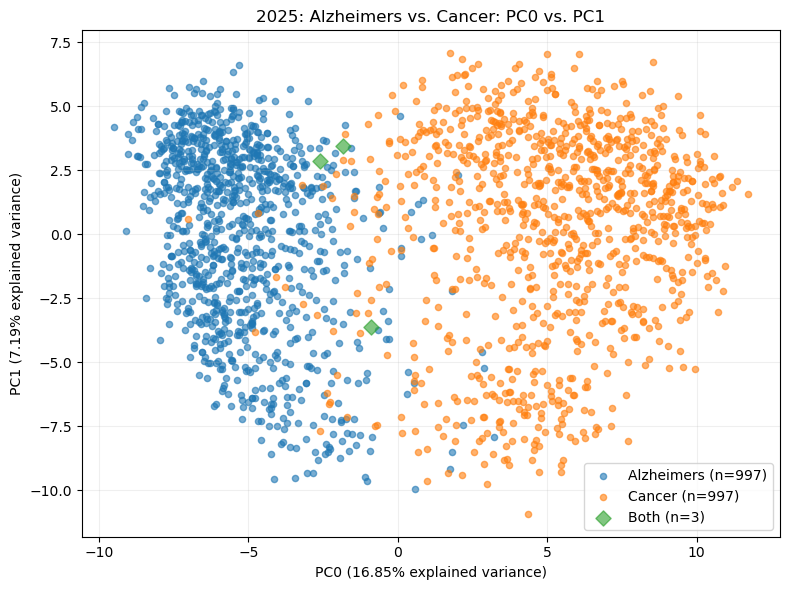

Saved: part2-2025-pc0-pc1.png


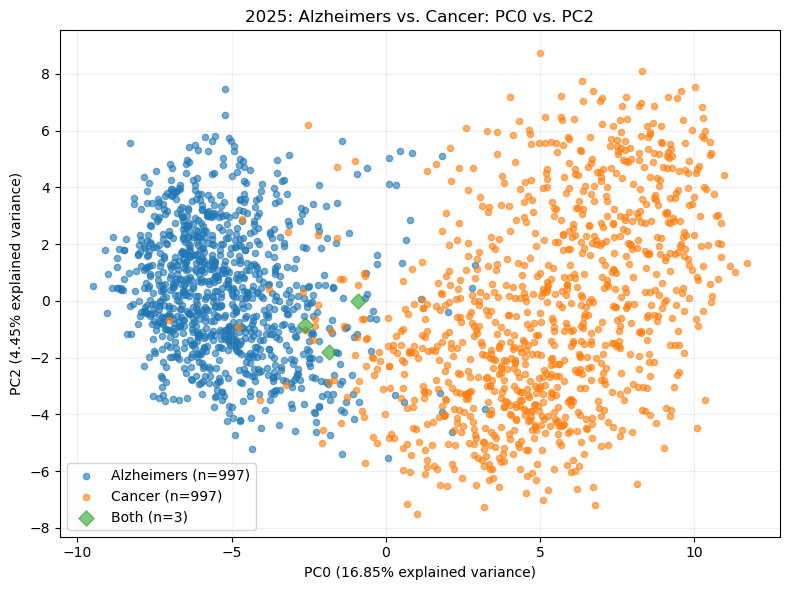

Saved: part2-2025-pc0-pc2.png


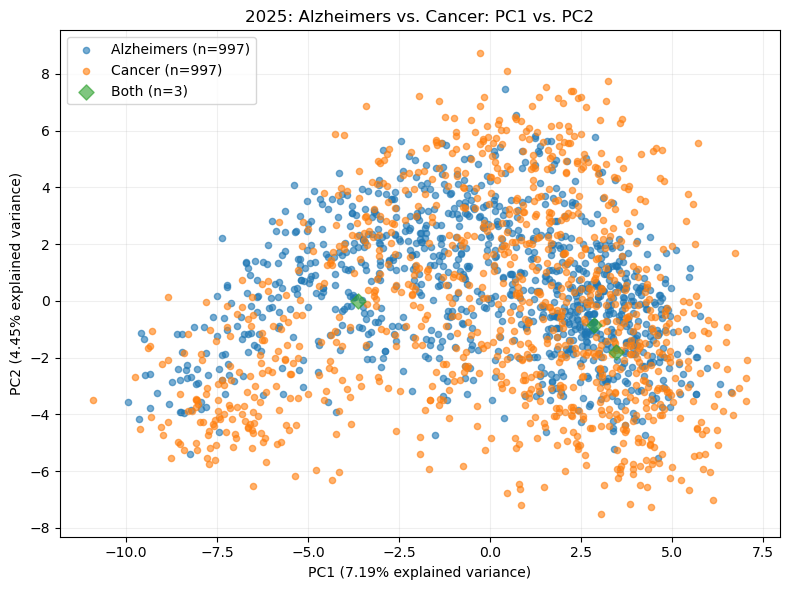

Saved: part2-2025-pc1-pc2.png


In [12]:
%matplotlib inline

import matplotlib.pyplot as plt

# Use the same colors and markers across all three plots
colors = COLORS

component_pairs = [(0, 1), (0, 2), (1, 2)]

for x_component, y_component in component_pairs:
    fig, ax = plt.subplots(figsize=(8, 6))

    # Select and plot each query group
    for label, color in colors.items():
        mask = labels_run == label

        ax.scatter(
            X_pca_run[mask, x_component],
            X_pca_run[mask, y_component],
            color=color,
            label=f"{label} (n={mask.sum()})",
            alpha=0.6,
            s=60 if label == "Both" else 20,
            marker="D" if label == "Both" else "o",
        )

    ax.set_xlabel(
        f"PC{x_component} "
        f"({variance_ratios_run[x_component]:.2%} explained variance)"
    )
    ax.set_ylabel(
        f"PC{y_component} "
        f"({variance_ratios_run[y_component]:.2%} explained variance)"
    )
    ax.set_title(
        f"{PLOT_TITLE}: PC{x_component} vs. PC{y_component}"
    )
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()

    # Save the figure before displaying it
    output_path = (
        FOLDER / f"{PLOT_PREFIX}-pc{x_component}-pc{y_component}.png"
    )
    fig.savefig(output_path, dpi=200, bbox_inches="tight")

    plt.show()
    plt.close(fig)

    print("Saved:", output_path.name)

### 11. Explore the interactive 3D plot

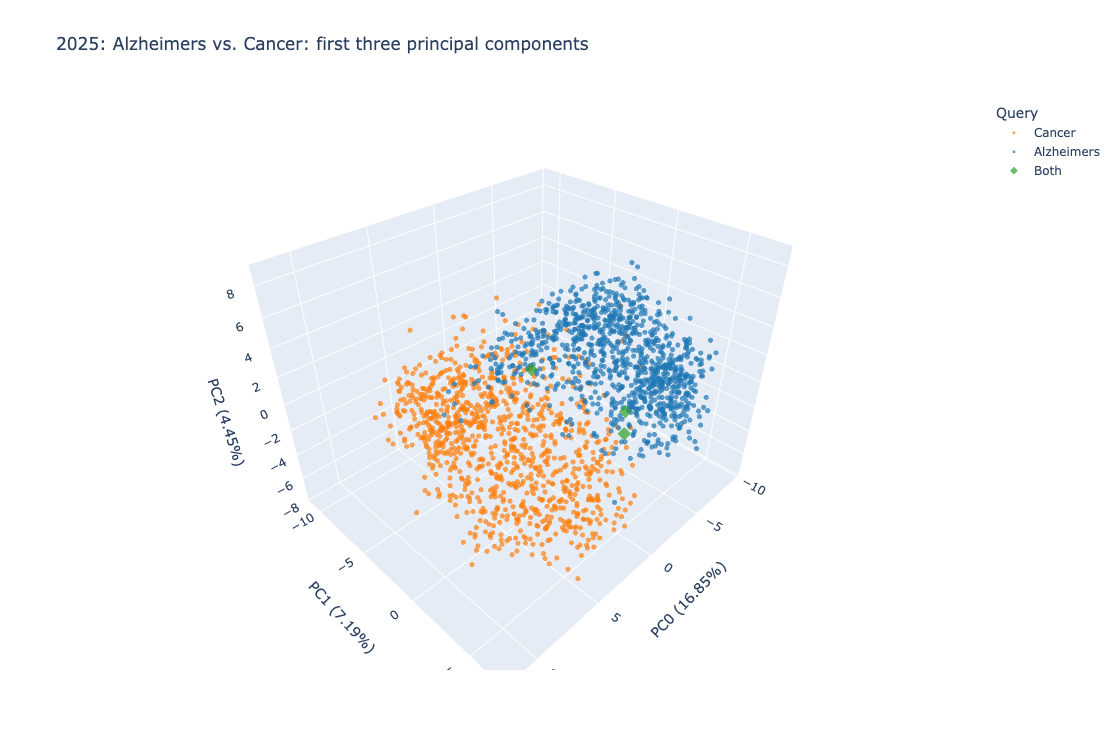

In [13]:
import pandas as pd
import plotly.express as px

# Align coordinates and metadata using the same PMID order
plot_data_run = pd.DataFrame({
    "PC0": X_pca_run[:, 0],
    "PC1": X_pca_run[:, 1],
    "PC2": X_pca_run[:, 2],
    "Query": labels_run,
    "PMID": pmids_run,
    "Title": [
        papers_run[pmid]["ArticleTitle"]
        for pmid in pmids_run
    ],
})

# Create an interactive 3D scatter plot
fig_run = px.scatter_3d(
    plot_data_run,
    x="PC0",
    y="PC1",
    z="PC2",
    color="Query",
    symbol="Query",
    color_discrete_map=COLORS,
    symbol_map=SYMBOLS,
    custom_data=["PMID", "Title"],
    opacity=0.7,
    title=f"{PLOT_TITLE}: first three principal components",
    height=750,
)

# Display the PMID, title, and coordinates when hovering
fig_run.update_traces(
    marker={"size": 3},
    hovertemplate=(
        "<b>PMID:</b> %{customdata[0]}<br>"
        "<b>Title:</b> %{customdata[1]}<br>"
        "PC0: %{x:.3f}<br>"
        "PC1: %{y:.3f}<br>"
        "PC2: %{z:.3f}"
        "<extra>%{fullData.name}</extra>"
    ),
)

# Make papers found in both searches easier to identify
fig_run.update_traces(
    marker={"size": 6},
    selector={"name": "Both"},
)

# Preserve relative axis scales and label explained variance
fig_run.update_layout(
    scene={
        "xaxis_title": f"PC0 ({variance_ratios_run[0]:.2%})",
        "yaxis_title": f"PC1 ({variance_ratios_run[1]:.2%})",
        "zaxis_title": f"PC2 ({variance_ratios_run[2]:.2%})",
        "aspectmode": "data",
    }
)

fig_run.show()

# Save a standalone interactive plot for this run.
fig_run.write_html(FOLDER / f"{PLOT_PREFIX}-pca-3d.html", include_plotlyjs=True)

### 12. Inspect selected papers

In [14]:
import textwrap

# Map each PMID to its row in the current PCA matrix
pmid_to_row_run = {
    pmid: i for i, pmid in enumerate(pmids_run)
}


def inspect_paper_run(pmid):
    """Display metadata and PCA coordinates for a selected selected paper."""
    pmid = str(pmid).strip()

    if pmid not in papers_run:
        print(f"PMID {pmid} was not found in the selected dataset.")
        return

    paper = papers_run[pmid]

    print("PMID:", pmid)
    print("Query label:", paper["query"])
    print("PubMed URL:", f"https://pubmed.ncbi.nlm.nih.gov/{pmid}/")

    print("\nTitle:")
    print(textwrap.fill(paper["ArticleTitle"], width=100))

    # Retrieve the coordinates for the same PMID
    row = pmid_to_row_run[pmid]

    print("\nPCA coordinates:")
    for component, value in enumerate(X_pca_run[row]):
        print(f"PC{component}: {value:.4f}")

    # Display the available abstract sections
    print("\nAbstract:")
    sections = paper.get("AbstractText") or []
    has_text = False

    for section in sections:
        text = section.get("text", "").strip()
        if not text:
            continue

        has_text = True
        heading = section.get("section", "")

        if heading:
            print(f"\n{heading}")

        print(textwrap.fill(text, width=100))
        print()

    if not has_text:
        print("No abstract available in the saved metadata.")

### Select PMIDs to inspect

In [16]:
# Enter selected PMIDs here, then run this cell. Leave empty to skip.
SELECTED_PMIDS = []
for pmid in SELECTED_PMIDS:
    print("=" * 100)
    inspect_paper_run(pmid)
    print()